# 03 · Feature Engineering

Notebook 02 produced the label table: one row per active customer per monthly snapshot, with
`churned` = "no booking in the next 60 days". Now we describe each of those customers **as they
looked on the snapshot date**.

### The one rule: point-in-time features

A feature for the 1 March snapshot may only use bookings **on or before 1 March**. Using anything
later is leakage: the model would look brilliant in testing and fail in production, where the
future isn't available. Every function in `src/features.py` filters by date first, and section 2
proves it with a test.

### Feature families

| Family | Features | Idea |
|---|---|---|
| **Recency & rhythm** | `recency_days`, `typical_gap_days`, `recency_vs_typical_gap`, `last_gap_vs_typical_gap` | Silence matters relative to how often *this* customer usually books (notebook 01) |
| **Frequency & trend** | `n_bookings`, `n_bookings_30d/90d`, `booking_trend_30d` | Is the customer slowing down? |
| **Experience** | cancellation rates, ratings, complaints, expert delays, `last_booking_bad` | Bad service drives people away |
| **Money** | `total_spend`, `avg_order_value`, `coupon_rate`, `avg_discount_pct` | Value and price sensitivity |
| **Profile** | `main_service`, `n_services_used`, `tenure_days`, `city`, `acquisition_channel` | Context |

**Not here yet:** support tickets, refunds and complaint resolution time from the original candidate
list. The synthetic data doesn't have them. Add them when the real tables arrive.

> ⚠️ **Synthetic data.** Results show how the method works, not facts about Snabbit.
> All analysis below uses the **training split only**. Looking at validation or test data while
> designing features is a quiet form of overfitting.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

import churn_definition as cd
import config
import features

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

bookings = cd.load_bookings(config.RAW_DIR / "bookings.csv")
customers = pd.read_csv(config.RAW_DIR / "customers.csv", parse_dates=["signup_date"])
labels = pd.read_csv(config.PROCESSED_DIR / "labels.csv", parse_dates=["as_of"])

table = features.build_features(bookings, customers, labels)
print(table.shape)
table.head(3).T

(92204, 33)


,0,1,2
customer_id,C000001,C000010,C000018
as_of,2025-04-01 00:00:00,2025-04-01 00:00:00,2025-04-01 00:00:00
churned,0,0,0
split,train,train,train
recency_days,22,17,1
days_since_first_booking,31,17,1
n_bookings,2,1,1
n_bookings_30d,1,1,1
n_bookings_90d,2,1,1
booking_trend_30d,0.5,1.0,1.0


## 1 · Missing values are information, not errors

Some features are blank for a reason. We **leave them as NaN** here and decide how to fill them in the
modelling step, because different models need different handling.

In [2]:
missing = table.isna().mean()
missing[missing > 0].rename("share missing").to_frame()

,share missing
last_gap_vs_typical_gap,0.063
avg_rating,0.043
rating_response_rate,0.007
avg_delay_minutes,0.007
avg_order_value,0.007


- `avg_rating`: the customer never rated a booking. "Never rates" may itself be a signal.
- `last_gap_vs_typical_gap`: only one booking so far, so there's no gap yet.
- `avg_order_value`, `avg_delay_minutes`, `rating_response_rate`: no *completed* booking yet.

## 2 · Leakage test

We rebuild one snapshot's features after **deleting every booking after the snapshot date**. If any
feature secretly used the future, the two versions would differ.

In [3]:
as_of = pd.Timestamp("2026-01-01")
ids = labels.loc[labels["as_of"] == as_of, "customer_id"]

with_future = features.snapshot_features(bookings, as_of, ids)
without_future = features.snapshot_features(bookings[bookings["day"] <= as_of], as_of, ids)

pd.testing.assert_frame_equal(with_future, without_future)
print("leakage test passed: features are identical without future bookings")

leakage test passed: features are identical without future bookings


## 3 · Which features carry signal on their own?

**AUC** answers: *if we pick one churner and one non-churner at random, how often does this feature
alone rank them correctly?* 0.5 is a coin flip, 1.0 is perfect. Direction "+" means higher values
go with more churn.

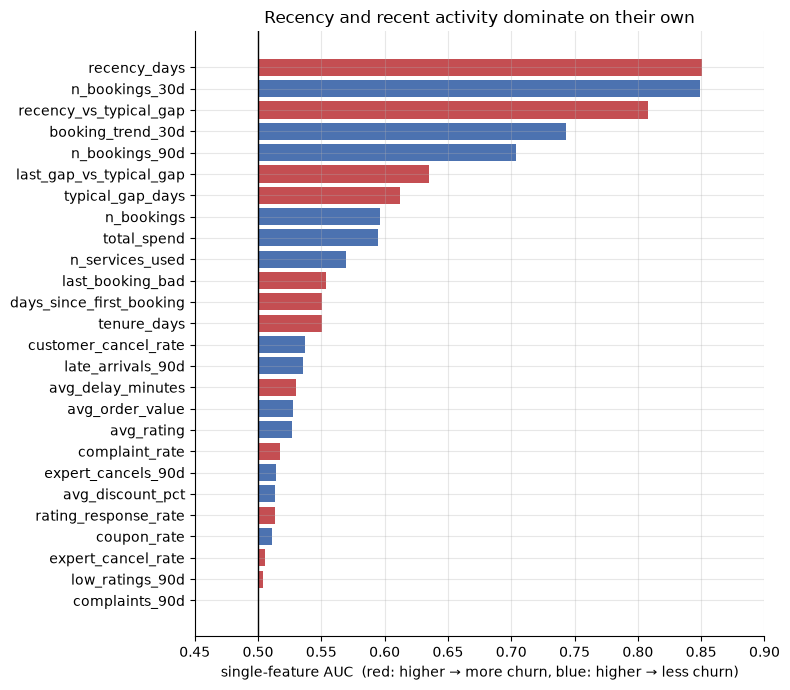

,auc,direction
feature,,
recency_days,0.850,+
n_bookings_30d,0.849,−
recency_vs_typical_gap,0.808,+
booking_trend_30d,0.743,−
n_bookings_90d,0.703,−
last_gap_vs_typical_gap,0.635,+
typical_gap_days,0.612,+
n_bookings,0.596,−
total_spend,0.595,−


In [4]:
train = table[table["split"] == "train"].copy()
numeric = train.select_dtypes("number").drop(columns="churned")

rows = []
for col in numeric:
    x = numeric[col]
    ok = x.notna()
    auc = roc_auc_score(train.loc[ok, "churned"], x[ok])
    rows.append({"feature": col, "auc": max(auc, 1 - auc), "direction": "+" if auc >= 0.5 else "−"})
single = pd.DataFrame(rows).sort_values("auc", ascending=False).set_index("feature")

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(single.index[::-1], single["auc"][::-1] - 0.5, left=0.5,
        color=["#C44E52" if d == "+" else "#4C72B0" for d in single["direction"][::-1]])
ax.axvline(0.5, color="black", lw=1)
ax.set(xlim=(0.45, 0.9), xlabel="single-feature AUC  (red: higher → more churn, blue: higher → less churn)",
       title="Recency and recent activity dominate on their own")
plt.tight_layout()
plt.show()
single

Recency and recent booking counts dominate, which we expected. The experience features look
almost useless here (AUC close to 0.5). **But a weak single-feature AUC doesn't mean a useless
feature.** Two things can hide a real signal:

1. **It's rare.** Only about 12% of customers had a bad last booking, so it barely moves a
   ranking across *everyone*.
2. **It's confounded.** Counts like `expert_cancels_90d` grow with the number of bookings. Busy
   customers have more chances for something to go wrong *and* are less likely to churn.

The fair test: compare customers who are **equally silent**.

## 4 · Signals hidden inside the same silence level

In [5]:
train["silence_band"] = pd.cut(train["recency_vs_typical_gap"], [0, 1, 2, 3, np.inf], right=False,
                               labels=["< 1× usual gap", "1–2×", "2–3×", "≥ 3×"])

bad_last = train.pivot_table(index="silence_band", columns="last_booking_bad", values="churned",
                             aggfunc="mean", observed=True)
bad_last.columns = ["last booking fine", "last booking bad"]
bad_last["ratio"] = bad_last["last booking bad"] / bad_last["last booking fine"]
bad_last

,last booking fine,last booking bad,ratio
silence_band,,,
< 1× usual gap,0.059,0.105,1.772
1–2×,0.141,0.240,1.704
2–3×,0.348,0.474,1.360
≥ 3×,0.729,0.843,1.157


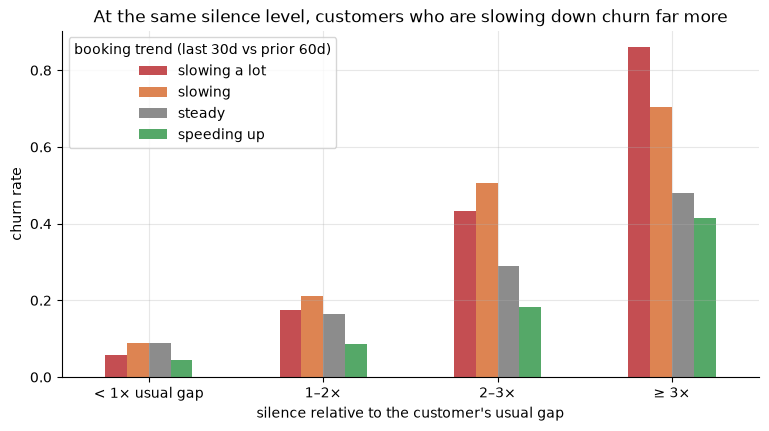

trend,slowing a lot,slowing,steady,speeding up
silence_band,,,,
< 1× usual gap,0.057,0.088,0.088,0.045
1–2×,0.175,0.211,0.166,0.087
2–3×,0.433,0.507,0.291,0.182
≥ 3×,0.861,0.705,0.481,0.415


In [6]:
train["trend"] = pd.cut(train["booking_trend_30d"], [-np.inf, -1.5, -0.5, 0.5, np.inf],
                        labels=["slowing a lot", "slowing", "steady", "speeding up"])
trend = train.pivot_table(index="silence_band", columns="trend", values="churned",
                          aggfunc="mean", observed=True)

fig, ax = plt.subplots(figsize=(9, 4.5))
trend.plot(kind="bar", ax=ax, rot=0, color=["#C44E52", "#DD8452", "#8C8C8C", "#55A868"])
ax.set(xlabel="silence relative to the customer's usual gap", ylabel="churn rate",
       title="At the same silence level, customers who are slowing down churn far more")
ax.legend(title="booking trend (last 30d vs prior 60d)")
plt.show()
trend

In [7]:
counts = train.pivot_table(index="silence_band", columns=train["expert_cancels_90d"].clip(upper=2),
                           values="churned", aggfunc="mean", observed=True)
counts.columns = ["0 expert cancels", "1", "2+"]
counts

,0 expert cancels,1,2+
silence_band,,,
< 1× usual gap,0.069,0.054,0.039
1–2×,0.161,0.134,0.097
2–3×,0.365,0.392,0.311
≥ 3×,0.734,0.830,0.843


**How to read these tables:**

- **A bad last booking raises churn at every silence level**: about 1.7–1.8× for customers who
  aren't yet overdue, shrinking to 1.2× once they're long overdue, when most are leaving anyway. That's the
  real signal that the single-feature AUC hid. It matters most early, which is exactly when retention can still act.
- **Booking trend matters most once a customer is overdue.** Among customers silent for 3× their
  usual gap, those who were slowing down churn far more often than those who were speeding up.
  Silence on its own can't tell those two groups apart.
- **Raw counts can mislead.** For customers who aren't yet overdue, *more* expert cancellations
  go with *less* churn. That's not because cancellations are good; heavy users simply have more
  bookings to be cancelled. That's why we include *rates* (`expert_cancel_rate`) alongside counts,
  and why tree models, which can combine features, should do better than any single rule.

## 5 · Categorical features

In [8]:
pd.concat({col: train.groupby(col)["churned"].agg(["mean", "size"])
           for col in ["main_service", "city", "acquisition_channel"]})

mean   size
main_service        cleaning     0.157  26554
                    dishwashing  0.182  12620
                    laundry      0.155  12520
city                Bengaluru    0.150  18231
                    Gurugram     0.175  13185
                    Mumbai       0.165  20278
acquisition_channel organic      0.165  18309
                    paid_social  0.165  12859
                    referral     0.156  10266
                    search_ads   0.160  10260

Small differences only. Gurugram is slightly higher, consistent with its slower expert arrival times
in the generator. Acquisition channel shows nothing, which is correct: the generator gave it no
effect. It's reassuring when a feature that *should* be useless looks useless.

## 6 · Redundant features

Pairs that are nearly identical add little and can confuse the coefficients of a linear model.

In [9]:
corr = numeric.corr(method="spearman").abs()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename("spearman").sort_values(ascending=False))
pairs[pairs > 0.8].to_frame()

,,spearman
days_since_first_booking,tenure_days,0.999
coupon_rate,avg_discount_pct,0.970
n_bookings,total_spend,0.928
recency_days,recency_vs_typical_gap,0.909
n_bookings,n_bookings_90d,0.858
days_since_first_booking,n_bookings,0.837
n_bookings,tenure_days,0.837
n_services_used,total_spend,0.810
days_since_first_booking,total_spend,0.805
total_spend,tenure_days,0.805


In [10]:
table.to_csv(config.PROCESSED_DIR / "features.csv", index=False)
print(f"saved {table.shape[0]:,} rows × {table.shape[1]} columns → data/processed/features.csv")

saved 92,204 rows × 33 columns → data/processed/features.csv


## 7 · Conclusions (synthetic data, provisional)

**1. 29 point-in-time features for 92,204 snapshot rows, proven leak-free.** Rebuilding a snapshot
without any future bookings gives identical features. Saved to `data/processed/features.csv`.

**2. Recency and recent activity are the strongest single signals** (AUC around 0.85). Any model has to
beat a "sort by days silent" baseline, and the modelling step will measure that explicitly.

**3. The extra value lives in combinations, not single features.** On their own, experience features
look like noise (AUC below 0.56). Among customers who are *equally silent*, though:
- a bad last booking raises churn about 1.7× for customers who aren't yet overdue;
- slowing down vs speeding up separates 86% from 42% churn among long-overdue customers.

This is why we'll compare a linear baseline with tree models, which pick up such interactions
on their own.

**4. Counts are confounded by activity; rates are fairer.** Expert cancellations *counts* look
protective for active customers only because heavy users have more bookings. We keep both counts and
rates and let validation decide.

**5. Some features are redundant**: `tenure_days` ≈ `days_since_first_booking` (0.999),
`coupon_rate` ≈ `avg_discount_pct` (0.97). Harmless for trees; for logistic regression we'll drop one of
each pair.

**6. Profile features carry little**, and acquisition channel carries none. That's correct here
(the generator gave it no effect), and a good sign that the analysis isn't inventing patterns.

### Notes for the real data
- **Timestamps:** we assumed a rating or complaint is known on the booking date. In reality ratings
  arrive later. Use the rating's *own* timestamp, or this becomes a subtle leak.
- **Booking created vs scheduled:** a booking *made* before the snapshot but *scheduled* after it is
  known at snapshot time and is a strong "still engaged" signal. Check which dates Snabbit stores.
- **New sources to add:** support tickets, refunds and complaint resolution time.
